# SCA Homework 1 – Forecasting Airline Passengers
Parts I–VI.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")

Matplotlib is building the font cache; this may take a moment.


In [2]:
# load data
df = pd.read_csv("data/Homework1_TSA130.csv")
df = df.dropna()
df["Date"] = pd.to_datetime(df["Date"], format="%b-%y")

y = df.set_index("Date")["Number of Passengers (x1000)"]
y = y.asfreq("MS")

print(len(y), "months, missing values:", y.isna().sum())
y.head()

130 months, missing values: 0


Date
2014-01-01    113.0
2014-02-01    119.0
2014-03-01    139.0
2014-04-01    129.0
2014-05-01    124.0
Freq: MS, Name: Number of Passengers (x1000), dtype: float64

## I. Visualisation

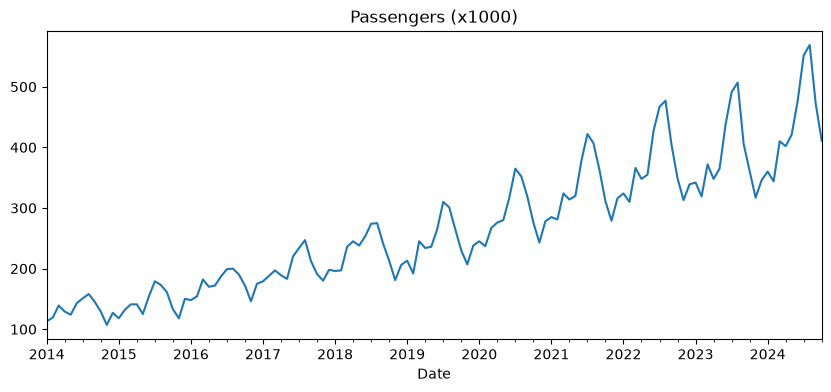

In [3]:
# time series
y.plot(figsize=(10, 4), title="Passengers (x1000)")
plt.show()

Plotting one line per year

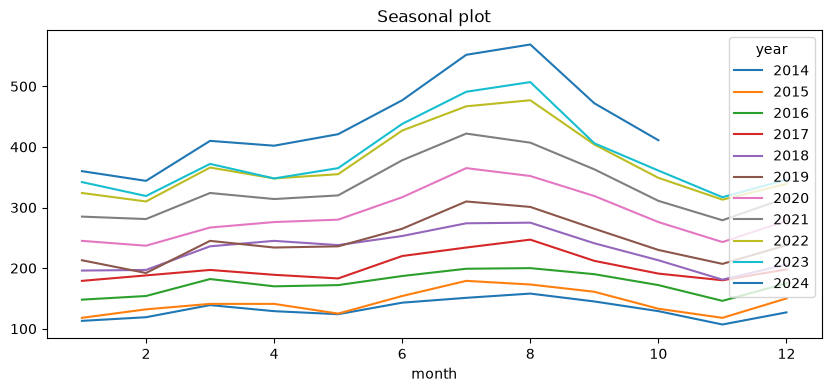

In [4]:

df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
table = df.pivot(index="month", columns="year", values="Number of Passengers (x1000)")
table.plot(figsize=(10, 4), title="Seasonal plot")
plt.show()

Total per year

In [5]:
y.groupby(y.index.year).sum()

Date
2014    1584.0
2015    1725.0
2016    2095.0
2017    2418.0
2018    2755.0
2019    2936.0
2020    3455.0
2021    4000.0
2022    4479.0
2023    4612.0
2024    4418.0
Name: Number of Passengers (x1000), dtype: float64

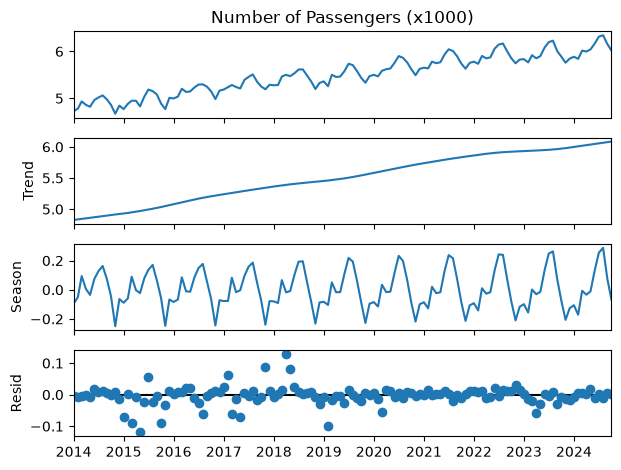

Date
2015-05-01   -3.832415
2017-11-01    3.017498
2018-04-01    4.326006
2019-02-01   -3.119425
Name: resid, dtype: float64

In [6]:
# decomposition of log(y) into trend, season and residual
stl = STL(np.log(y), period=12, robust=True).fit()
stl.plot()
plt.show()

#Months with a large residual
resid = stl.resid
z = (resid - resid.mean()) / resid.std()
z[abs(z) > 3]

- 130 months (Jan-14 to Oct-24), 2024 runs only to October.
- A few STL residuals stand out (May-15, Apr-18), but they are small in absolute terms.
- Clear upward trend (flattening in 2023–24) and yearly seasonality, with a peak in Jul – Aug.
- Seasonal swings grow with the level -> multiplicative, so we model log(y).

## II. Stationarity
ADF test: H₀ = unit root (non-stationary), so p < 0.05 means stationary.

In [7]:
ly = np.log(y)
for name, x in [("log y", ly), ("first difference", ly.diff()),
                ("seasonal difference", ly.diff(12)), ("both differences", ly.diff().diff(12))]:
    print(name, " ADF p =", round(adfuller(x.dropna())[1], 3))

log y  ADF p = 0.638
first difference  ADF p = 0.017
seasonal difference  ADF p = 0.067
both differences  ADF p = 0.004


- log y: ADF p = 0.64, so non-stationary.
- First difference: ADF p = 0.017, but the seasonal pattern is still there, so a seasonal difference is also needed.
- Both differences: ADF p = 0.004, so stationary. Use d = 1, D = 1.

## III. Models
Last 12 months are the test set (for part IV).

In [8]:
train = y[:-12]
test_set = y[-12:]

### (a) Exponential smoothing (Holt-Winters)
Try all trend/seasonal options, pick the lowest AIC.

In [9]:
results = []
for trend in ["additive", "multiplicative"]:
    for damped in [False, True]:
        for seasonal in ["additive", "multiplicative"]:
            m = ExponentialSmoothing(train, trend=trend, damped_trend=damped,
                                     seasonal=seasonal, seasonal_periods=12).fit()
            results.append([trend, damped, seasonal, m.aic])

results = pd.DataFrame(results, columns=["trend", "damped", "seasonal", "AIC"])
results.sort_values("AIC")

,trend,damped,seasonal,AIC
1,additive,False,multiplicative,590.976821
5,multiplicative,False,multiplicative,592.505838
7,multiplicative,True,multiplicative,592.515549
3,additive,True,multiplicative,597.001134
0,additive,False,additive,622.042682
4,multiplicative,False,additive,624.635751
6,multiplicative,True,additive,626.551587
2,additive,True,additive,627.737036


In [10]:
# best model
ets = ExponentialSmoothing(train, trend="additive", damped_trend=False,
                           seasonal="multiplicative", seasonal_periods=12).fit()
ets.params

{'smoothing_level': np.float64(0.2859776589966525),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.6498818482545372),
 'damping_trend': nan,
 'initial_level': np.float64(130.55918495540774),
 'initial_trend': np.float64(2.6883772601306815),
 'initial_seasons': array([0.8469876 , 0.88336   , 0.99187067, 0.91866688, 0.85119235,
        0.96989576, 1.02780266, 1.04247066, 0.95693956, 0.84953208,
        0.73633844, 0.8778012 ]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

### (b) SARIMA on log y
d = 1, D = 1 from part II. Look at ACF/PACF, then try small models and pick the lowest AIC.

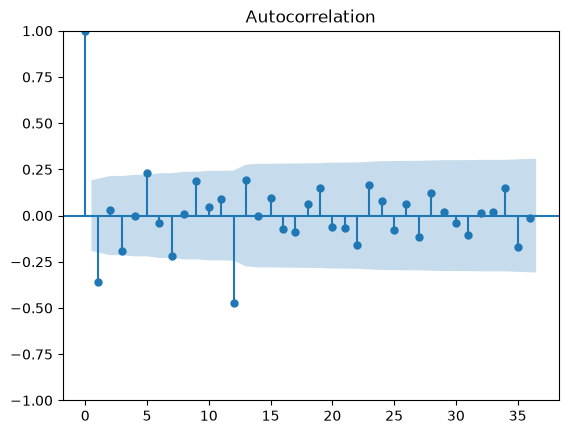

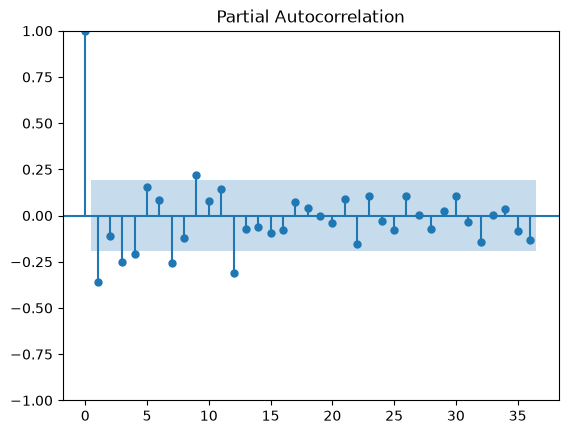

In [11]:
log_train = np.log(train)
x = log_train.diff().diff(12).dropna()

plot_acf(x, lags=36)
plot_pacf(x, lags=36)
plt.show()

ACF spikes at lag 1 and 12, so MA(1) and SMA(1).

In [12]:
results = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    m = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
    results.append([p, q, P, Q, m.aic])

results = pd.DataFrame(results, columns=["p", "q", "P", "Q", "AIC"])
results.sort_values("AIC").head()

,p,q,P,Q,AIC
5,0,1,0,1,-347.325861
7,0,1,1,1,-347.252555
6,0,1,1,0,-346.210431
17,1,1,0,1,-346.044650
9,0,2,0,1,-345.681883


In [13]:
# best model
sarima = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima.summary())

#res should be white noise with p > 0.05
acorr_ljungbox(sarima.resid[13:], lags=[12, 24])

                                     SARIMAX Results                                      
Dep. Variable:       Number of Passengers (x1000)   No. Observations:                  118
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 176.663
Date:                            Sat, 31 Oct 2026   AIC                           -347.326
Time:                                    13:26:46   BIC                           -339.364
Sample:                                01-01-2014   HQIC                          -344.100
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4709      0.090     -5.232      0.000      -0.647      -0.295
ma.S.L12      -0.5835      0.114   

,lb_stat,lb_pvalue
12,12.734534,0.388628
24,23.152970,0.510783


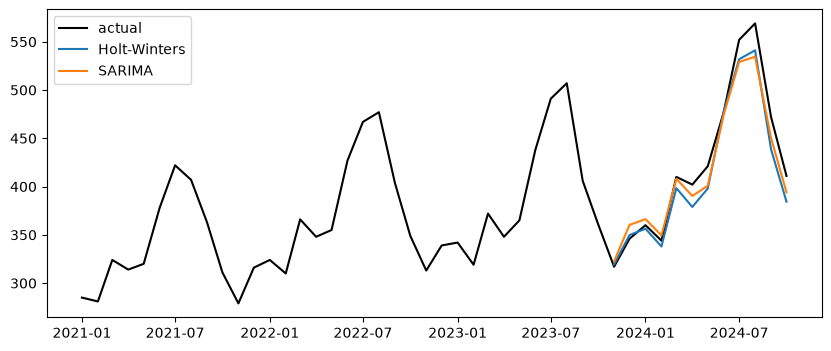

In [14]:
#Forecasts for the test year
fc_ets = ets.forecast(12)
fc_sarima = np.exp(sarima.forecast(12))

plt.figure(figsize=(10, 4))
plt.plot(y["2021":], color="black", label="actual")
plt.plot(fc_ets, label="Holt-Winters")
plt.plot(fc_sarima, label="SARIMA")
plt.legend()
plt.show()

- ETS: additive trend + multiplicative seasonality has the lowest AIC.
- SARIMA(0,1,1)(0,1,1)_12 on log y (the "airline model"); both MA terms are significant, Ljung-Box p > 0.05 so white-noise residuals.
- Both models follow the test year closely

## IV. Model Evaluation

Both models are evaluated on the last 12 months, excluded from model fitting.

Bias is forecast minus actual: positive means overforecasting; negative means underforecasting. Bias, RMSE and MAE are in thousands of passengers; MAPE is a percentage.

In [15]:
def evaluate_forecast(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    error = forecast - actual

    return {
        "Bias": np.mean(error),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAE": np.mean(np.abs(error)),
        "MAPE (%)": 100 * np.mean(np.abs(error / actual)),
    }

evaluation = pd.DataFrame({
    "Holt-Winters": evaluate_forecast(test_set, fc_ets),
    "SARIMA": evaluate_forecast(test_set, fc_sarima),
}).T

evaluation = evaluation.sort_values("RMSE")
display(evaluation.round(3))


,Bias,RMSE,MAE,MAPE (%)
SARIMA,-8.421,16.673,13.685,3.075
Holt-Winters,-14.059,18.894,15.214,3.413


### Evaluation results and conclusion

On the held-out period November 2023-October 2024, SARIMA has lower RMSE (16.673 versus 18.894), MAE (13.685 versus 15.214), and MAPE (3.075% versus 3.413%) than Holt-Winters. SARIMA is therefore preferred for forecast accuracy on this test period.

Both models have negative bias, so they underforecast demand on average. SARIMA's bias is -8.421 thousand passengers per month (about 8,421 passengers below actual demand), compared with -14.059 thousand for Holt-Winters. SARIMA also has the smaller absolute bias. Its MAE corresponds to an average absolute error of about 13,685 passengers per month.


## V. Forecasting

The observations end in October 2024. Therefore, the remainder-of-year forecast covers **November and December 2024**. All values below are in **thousands of passengers**.

We retain the model specifications selected in Part III and refit each model using all 130 observations (January 2014-October 2024). The held-out evaluation in Part IV remains unchanged.

### 1. Refit and forecast

Holt-Winters uses an additive, undamped trend and multiplicative seasonality. SARIMA uses order (0,1,1)(0,1,1,12) on log passengers. Exponentiating the SARIMA log-scale point forecast gives its **median** on the original passenger scale, consistent with the back-transformation used in Part IV.


In [16]:
# Refit the selected models on all available observations
ets_full = ExponentialSmoothing(
    y, trend="additive", damped_trend=False,
    seasonal="multiplicative", seasonal_periods=12
).fit()

sarima_full = SARIMAX(
    np.log(y), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)
).fit(disp=False)

# Forecast only the remaining months of the final observed year
h = 12 - y.index[-1].month
if h < 1:
    raise ValueError("The observations already cover the full calendar year.")

hw_point = ets_full.forecast(h)
sarima_prediction = sarima_full.get_forecast(steps=h)
sarima_point = np.exp(sarima_prediction.predicted_mean)

forecast_v = pd.DataFrame({
    "Holt-Winters": hw_point,
    "SARIMA (median)": sarima_point
})
display(forecast_v.round(3))


,Holt-Winters,SARIMA (median)
2024-11-01,358.709,365.208
2024-12-01,392.414,404.153


### 2. Prediction intervals

We report **central 95% prediction intervals for each future month**.

- **Holt-Winters:** simulate 10,000 future paths using the fitted model and resampled, centered relative residuals. Relative residuals support an error scale that grows with the series level. The 2.5th and 97.5th percentiles give approximate prediction limits.
- **SARIMA:** calculate the model's 95% forecast interval on the log scale, then exponentiate both endpoints to obtain the interval in thousands of passengers.






In [17]:
# Holt-Winters: simulation with centered relative residuals
n_simulations = 10000
rng = np.random.default_rng(42)
relative_errors = ((y - ets_full.fittedvalues)
                   / ets_full.fittedvalues).dropna().to_numpy()
relative_errors = relative_errors - relative_errors.mean()
simulated_errors = rng.choice(
    relative_errors, size=(h, n_simulations), replace=True
)

hw_paths = ets_full.simulate(
    h, anchor="end", repetitions=n_simulations,
    error="mul", random_errors=simulated_errors
)
hw_lower, hw_upper = np.quantile(
    np.asarray(hw_paths), [0.025, 0.975], axis=1
)

# SARIMA: transform the log-scale prediction interval back to passengers
sarima_interval = np.exp(sarima_prediction.conf_int(alpha=0.05))

hw_forecast_table = pd.DataFrame({
    "Point forecast": hw_point,
    "Lower 95%": hw_lower,
    "Upper 95%": hw_upper
})
sarima_forecast_table = pd.DataFrame({
    "Point forecast": sarima_point,
    "Lower 95%": sarima_interval.iloc[:, 0],
    "Upper 95%": sarima_interval.iloc[:, 1]
})

forecast_table_v = pd.concat(
    {"Holt-Winters": hw_forecast_table, "SARIMA": sarima_forecast_table},
    names=["Model", "Month"]
)
display(forecast_table_v.round(3))


Point forecast  Lower 95%  Upper 95%
Model        Month                                           
Holt-Winters 2024-11-01         358.709    324.870    394.697
             2024-12-01         392.414    355.157    433.319
SARIMA       2024-11-01         365.208    336.191    396.728
             2024-12-01         404.153    367.851    444.037

### 3. Historical observations and forecasts

The left panels show all historical observations. The right panels zoom in on the recent period so that the two forecast months and their prediction intervals are visible. Shaded regions show the central 95% prediction intervals. The dashed vertical line marks the last observed month.


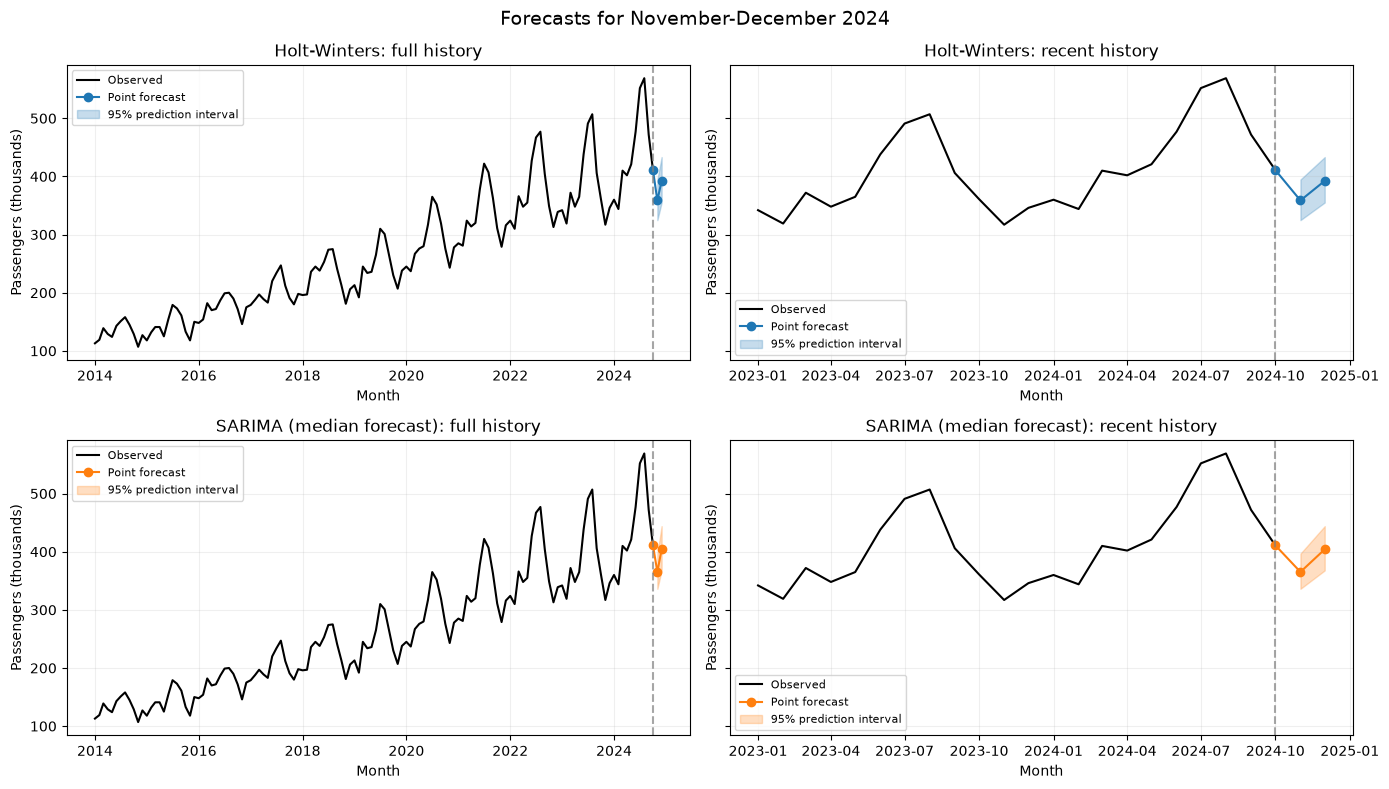

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey="row")

model_forecasts = [
    ("Holt-Winters", hw_forecast_table, "tab:blue"),
    ("SARIMA (median forecast)", sarima_forecast_table, "tab:orange")
]

for row, (name, table, color) in enumerate(model_forecasts):
    # Connect the point forecasts to the last historical observation
    forecast_line = pd.concat([y.iloc[-1:], table["Point forecast"]])

    for col, start in enumerate([y.index[0], pd.Timestamp("2023-01-01")]):
        ax = axes[row, col]
        history = y.loc[start:]
        ax.plot(history.index, history, color="black", label="Observed")
        ax.plot(forecast_line.index, forecast_line, color=color,
                marker="o", label="Point forecast")
        ax.fill_between(table.index, table["Lower 95%"], table["Upper 95%"],
                        color=color, alpha=0.25, label="95% prediction interval")
        ax.axvline(y.index[-1], color="gray", linestyle="--", alpha=0.7)
        ax.set_title(f"{name}: {'full history' if col == 0 else 'recent history'}")
        ax.set_ylabel("Passengers (thousands)")
        ax.set_xlabel("Month")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

fig.suptitle("Forecasts for November-December 2024", fontsize=14)
fig.tight_layout()
plt.show()


### 4. Interpretation

Both models forecast a decrease from the October observation to November, followed by an increase in December.

- **Holt-Winters:** November's point forecast is 358.709 thousand passengers, with an approximate 95% prediction interval of [324.870, 394.697]. December's forecast is 392.414, with interval [355.157, 433.319].
- **SARIMA:** November's median forecast is 365.208 thousand passengers, with 95% prediction interval [336.191, 396.728]. December's median forecast is 404.153, with interval [367.851, 444.037].

SARIMA gives higher point forecasts for both months, although the two models' intervals overlap. For both models, the prediction interval is wider for December than for November, reflecting additional forecast uncertainty further into the future. These are forecasts conditional on the data through October 2024; no November or December observations were used in fitting.


## VI. Advising
Forecast until Dec-29 with the models from part V. For the 95% bounds we simulate 10,000 paths per model.

In [19]:
# months from Nov-24 up to Dec-29
h_long = (2029 - y.index[-1].year) * 12 + 12 - y.index[-1].month
future = pd.date_range(y.index[-1] + pd.DateOffset(months=1), periods=h_long, freq="MS")

fc_long = pd.DataFrame({
    "Holt-Winters": np.asarray(ets_full.forecast(h_long)),
    "SARIMA": np.exp(np.asarray(sarima_full.forecast(h_long)))
}, index=future)

# simulated paths: one row per month, one column per path
rng = np.random.default_rng(42)
hw_errors = rng.choice(relative_errors, size=(h_long, n_simulations), replace=True)
hw_sim = pd.DataFrame(np.asarray(ets_full.simulate(
    h_long, anchor="end", repetitions=n_simulations,
    error="mul", random_errors=hw_errors)), index=future)
sarima_sim = pd.DataFrame(np.exp(np.asarray(sarima_full.simulate(
    h_long, anchor="end", repetitions=n_simulations, rng=rng))), index=future)
sims = {"Holt-Winters": hw_sim, "SARIMA": sarima_sim}

### Next year
Capacity: in Aug-24 the 50 planes carried 569k passengers, so one plane carries about 11.4k passengers per month. For the number of planes we use the 95% upper bound of SARIMA, since SARIMA was the best model in part IV.

In [20]:
# capacity per plane: 50 planes carried the peak month of 2024
per_plane = y["2024"].max() / 50

next_year = pd.DataFrame({
    "HW forecast": fc_long["Holt-Winters"],
    "SARIMA forecast": fc_long["SARIMA"],
    "SARIMA 95% upper": sarima_sim.quantile(0.95, axis=1),
}).loc[:"2025"]
next_year["Planes needed"] = np.ceil(next_year["SARIMA 95% upper"] / per_plane).astype(int)
next_year.index = next_year.index.strftime("%b-%y")
display(next_year.round(1))

# peak month of 2025 in every path
peak_2025 = pd.DataFrame({name: sim.loc["2025"].max() for name, sim in sims.items()})
pd.DataFrame({
    "2025 total": fc_long.loc["2025"].sum(),
    "95% peak": peak_2025.quantile(0.95),
    "Planes needed": np.ceil(peak_2025.quantile(0.95) / per_plane),
    "P(peak > 50 planes)": (peak_2025 > 50 * per_plane).mean(),
}).round(2)

,HW forecast,SARIMA forecast,SARIMA 95% upper,Planes needed
Nov-24,358.7,365.2,390.9,35
Dec-24,392.4,404.2,437.1,39
Jan-25,405.8,414.8,452.1,40
Feb-25,385.5,396.1,435.5,39
Mar-25,456.1,466.4,515.8,46
Apr-25,440.4,450.7,501.5,45
May-25,457.6,466.6,522.0,46
Jun-25,526.5,542.2,611.1,54
Jul-25,604.8,614.1,695.9,62
Aug-25,618.6,625.4,711.7,63


,2025 total,95% peak,Planes needed,P(peak > 50 planes)
Holt-Winters,5641.25,684.53,61.0,0.96
SARIMA,5812.63,716.08,63.0,0.91


### Longer horizon (2025-2029)

In [21]:
annual = y[:"2023"].groupby(y[:"2023"].index.year).sum()
print("growth 2014-2023:", round(annual.diff().mean()), "thousand or",
      round(100 * ((annual[2023] / annual[2014]) ** (1 / 9) - 1), 1), "% per year")

long_term = {}
for name, sim in sims.items():
    total = sim.groupby(sim.index.year).sum()
    peak = sim.groupby(sim.index.year).max()
    long_term[name] = pd.DataFrame({
        "Total (median)": total.median(axis=1),
        "Planes (median peak)": np.ceil(peak.median(axis=1) / per_plane),
        "Planes (95% peak)": np.ceil(peak.quantile(0.95, axis=1) / per_plane),
    }).loc[2025:]
pd.concat(long_term, axis=1).round(0)

growth 2014-2023: 336 thousand or 12.6 % per year


Holt-Winters                                                SARIMA  \
     Total (median) Planes (median peak) Planes (95% peak) Total (median)   
2025         5643.0                 55.0              61.0         5816.0   
2026         6014.0                 59.0              68.0         6456.0   
2027         6390.0                 63.0              74.0         7159.0   
2028         6763.0                 67.0              80.0         7943.0   
2029         7138.0                 71.0              87.0         8814.0   

                                             
     Planes (median peak) Planes (95% peak)  
2025                 56.0              63.0  
2026                 62.0              77.0  
2027                 69.0              95.0  
2028                 77.0             117.0  
2029                 85.0             145.0

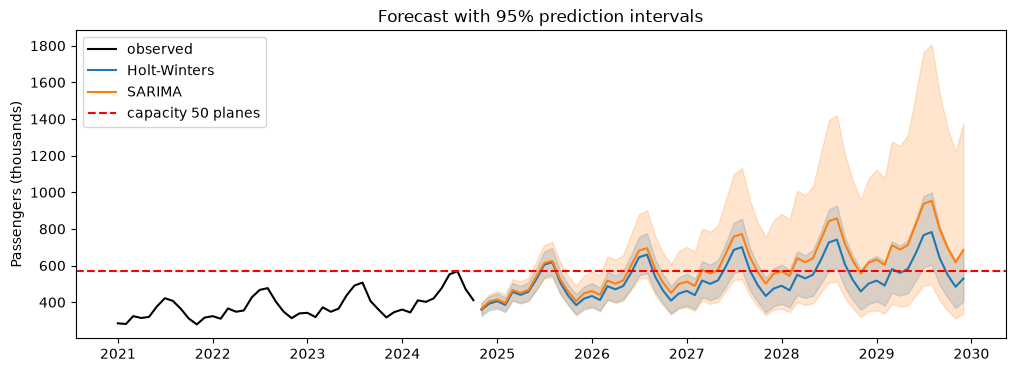

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(y["2021":], color="black", label="observed")
for (name, sim), color in zip(sims.items(), ["tab:blue", "tab:orange"]):
    plt.plot(fc_long[name], color=color, label=name)
    plt.fill_between(sim.index, sim.quantile(0.025, axis=1), sim.quantile(0.975, axis=1),
                     color=color, alpha=0.2)
plt.axhline(50 * per_plane, color="red", linestyle="--", label="capacity 50 planes")
plt.title("Forecast with 95% prediction intervals")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.show()

### Conclusion
- The models give almost the same forecast for 2025 (difference 1-7%, SARIMA a bit higher). Total for 2025 is around 5.6-5.8 million, so 22-26% more than in 2023.
- After 2025 they go apart. Holt-Winters adds about 375k passengers per year, SARIMA grows about 11% per year. Both fit the past (on average +336k or 12.6% per year), so we can't really say which one is right.
- The 2025 peak is in August and with 95% probability it stays below 685-716k. For this we need 61-63 planes, so 50 is not enough (more than 90% chance that the peak is higher than what 50 planes can carry).
- With 42 planes we are fine until February, from March we need 45-46. So the repairs should be done before March, not just before summer.

### Advice
- Lease about 13 extra planes for June-September 2025.
- Invest in more planes for the long term. In 2029 the median peak already needs 71 (HW) to 85 (SARIMA) planes. We would buy around 4 planes per year (the HW path) and lease on top of that if demand grows faster.
- Redo the forecast every year, because the intervals get very wide after a few years (especially SARIMA).

Assumptions: every plane carries the same number of passengers per month (with Aug-23 instead it is 10.1k per plane and we need about 12% more planes), no maintenance downtime, and trend and seasonality stay the same.